In [1]:
from pynq import Overlay, allocate
from pynq.lib.video import *
import numpy as np
import PIL.Image

ol = Overlay("./base.bit")

dma_send = ol.axi_dma_0.sendchannel
dma_recv = ol.axi_dma_0.recvchannel

/usr/local/share/pynq-venv/lib/python3.10/site-packages/pynq/bitstream.py:133: UserWarning: The provided name './base.bit' resulted in multiple possible matches:
 - /home/xilinx/jupyter_notebooks/PWZ/base.bit
 - /usr/local/share/pynq-venv/lib/python3.10/site-packages/pynq/overlays/./base/./base.bit
The first entry of this list, '/home/xilinx/jupyter_notebooks/PWZ/base.bit', will be used, please provide the full path in case your target file was a different one in this list.
  warnings.warn(msg, UserWarning)


In [15]:
mipi = ol.mipi
videomode = VideoMode(1280, 720, 24)
mipi.configure(videomode)
mipi.start()

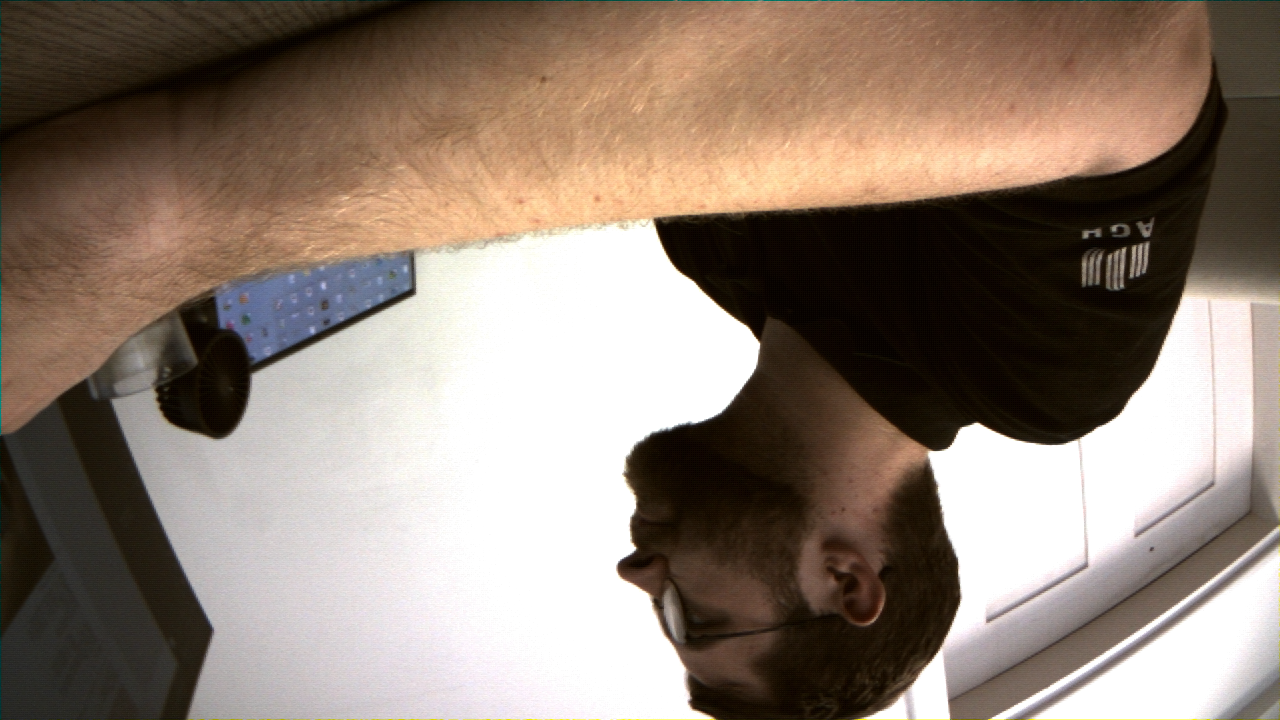

In [16]:
import cv2

shape = (720, 1280)
input_buffer = allocate(shape=shape, dtype=np.uint32)
output_buffer = allocate(shape=shape, dtype=np.uint32)
frame = mipi.readframe()
input_buffer[:] = (frame[:,:,2].astype(np.uint32) << 16 |
                   frame[:,:,1].astype(np.uint32) << 8 |
                   frame[:,:,0].astype(np.uint32)
                  )
dma_send.transfer(input_buffer)
dma_recv.transfer(output_buffer)
dma_send.wait()
dma_recv.wait()
image = np.empty((720, 1280, 3), dtype=np.uint8)
image[:,:,0] = (output_buffer >> 16).astype(np.uint8)
image[:,:,1] = (output_buffer >> 8).astype(np.uint8)
image[:,:,2] = (output_buffer).astype(np.uint8)

PIL.Image.fromarray(image)

In [17]:
displayport = DisplayPort()
displayport.configure(VideoMode(1280, 720, 24), PIXEL_RGB)

from time import time

for _ in range (3000):
    start = time()
    dp_frame_buffer = displayport.newframe()
    dpnewframe = time() - start
    
    start = time()
    frame = mipi.readframe()
    input_buffer[:] = (frame[:,:,2].astype(np.uint32) << 16 |
                       frame[:,:,1].astype(np.uint32) << 8 |
                       frame[:,:,0].astype(np.uint32)
                      )
    mipireadframe = time() - start
    
    start = time()
    dma_send.transfer(input_buffer)
    dma_recv.transfer(output_buffer)
    dma_send.wait()
    dma_recv.wait()
    dmatransfer = time() - start

    start = time()
    buf = np.array(output_buffer, copy=True)
    #image[:,:,2] = (buf >> 16)
    #image[:,:,1] = (buf >> 8)
    #image[:,:,0] = (buf)
    #dp_frame_buffer[:shape[0], :shape[1]] = image
    dp_frame_buffer[:shape[0],:shape[1],2] = (buf >> 16)
    dp_frame_buffer[:shape[0],:shape[1],1] = (buf >> 8)
    dp_frame_buffer[:shape[0],:shape[1],0] = (buf)
    
    concatwrite = time() - start

    displayport.writeframe(dp_frame_buffer)

    
    print(dpnewframe, mipireadframe, dmatransfer, concatwrite)


0.0034728050231933594 0.035330772399902344 0.009828567504882812 0.041600704193115234
0.0008292198181152344 0.027332782745361328 0.009820938110351562 0.043804168701171875
0.00012731552124023438 0.02706146240234375 0.00981760025024414 0.041835784912109375
0.00012731552124023438 0.027935028076171875 0.009918689727783203 0.04183149337768555
0.0007886886596679688 0.027353286743164062 0.009812355041503906 0.04413318634033203
0.00012493133544921875 0.02734994888305664 0.009826183319091797 0.04195261001586914
0.000125885009765625 0.02789926528930664 0.009916305541992188 0.04170560836791992
0.0007839202880859375 0.027217864990234375 0.009810447692871094 0.041474342346191406
0.000125885009765625 0.027266502380371094 0.009827136993408203 0.044168949127197266
0.00012922286987304688 0.028390884399414062 0.009928226470947266 0.04179668426513672
0.000797271728515625 0.027099609375 0.009824752807617188 0.04245138168334961
0.00012683868408203125 0.027364730834960938 0.009814262390136719 0.0420484542846

Exception ignored in: <function PynqBuffer.__del__ at 0xffff66018700>
Traceback (most recent call last):
  File "/usr/local/share/pynq-venv/lib/python3.10/site-packages/pynq/buffer.py", line 62, in __del__
    def __del__(self):
KeyboardInterrupt: 


0.00012493133544921875 0.027776241302490234 0.009902477264404297 0.041796207427978516
0.00014829635620117188 0.032825469970703125 0.009813308715820312 0.04205465316772461
0.00013065338134765625 0.027403831481933594 0.009827613830566406 0.04149341583251953
0.00012350082397460938 0.027287006378173828 0.009833335876464844 0.04259300231933594
0.0008082389831542969 0.02736520767211914 0.00981283187866211 0.04151439666748047
0.00012540817260742188 0.027282238006591797 0.009866714477539062 0.04183483123779297
0.000125885009765625 0.028310298919677734 0.009946823120117188 0.041437625885009766
0.0008168220520019531 0.02706146240234375 0.009840011596679688 0.04193592071533203
0.000125885009765625 0.027509212493896484 0.00982046127319336 0.04156064987182617
0.00012731552124023438 0.02764415740966797 0.009757518768310547 0.042584896087646484
0.000804901123046875 0.028289318084716797 0.009840965270996094 0.041513919830322266
0.00012636184692382812 0.027155399322509766 0.009825706481933594 0.0418372

In [18]:
displayport.close()
mipi.stop()